# Εργασία 1 – Επιβλεπόμενη Μάθηση 

# Βιβλιοθήκες

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Μέρος 1 – Λογιστική Παλινδρόμηση

# Dataset

In [2]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print(df.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


## Περιγραφή Μεταβλητών
- Pregnancies = Πόσες εγκυμοσύνες είχε το άτομο
- Glucose = Περιεκτικότητα γλυκόζης στο αίμα (mg/dl)
- BloodPressure = Διαστολική αρτηριακή πίεση αίματος (mmHg)
- SkinThickness = Πάχος δέρματος (mm)
- Insulin = Συγκέντρωση ινσουλίνης στο αίμα (μU/ml)
- BMI = Δείκτης Μάζας Σώματος (kg/m2)
- DiabetesPedigreeFunction = δείκτης οικογενειακής προδιάθεσης για σακχαρώδη διαβήτη (κληρονομική προδιάθεση)
- Age = Ηλικία 
- Outcome = Αποτέλεσμα. Δείχνει αν το άτομο έχει διαβήτη ή όχι (positive=1 , negative=0) 

In [4]:
df.describe().loc[['mean', 'std', 'min', 'max']]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


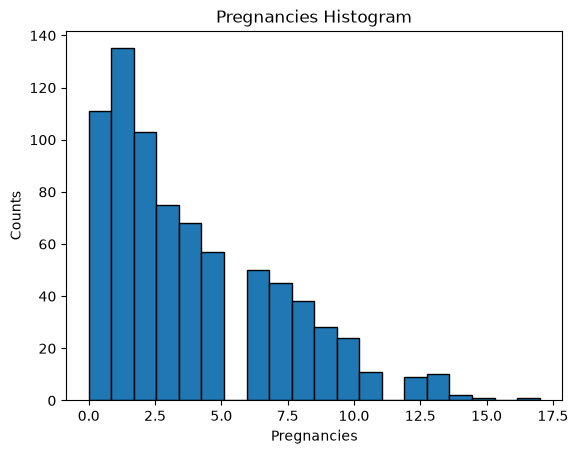

In [5]:
df['Pregnancies'].hist(bins=20, edgecolor='black')
plt.title('Pregnancies Histogram')
plt.xlabel('Pregnancies')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

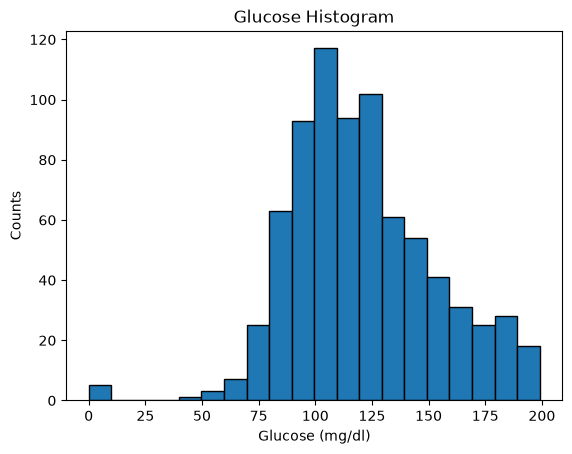

In [6]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Glucose Histogram')
plt.xlabel('Glucose (mg/dl)')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

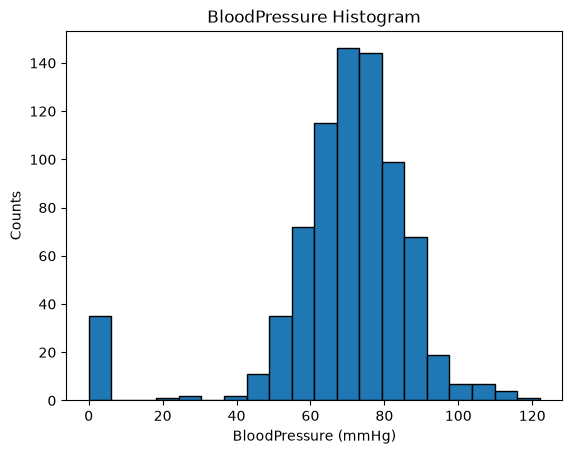

In [7]:
df['BloodPressure'].hist(bins=20, edgecolor='black')
plt.title('BloodPressure Histogram')
plt.xlabel('BloodPressure (mmHg)')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

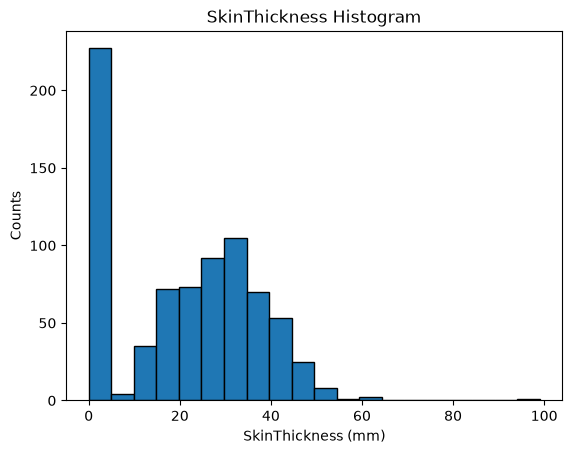

In [8]:
df['SkinThickness'].hist(bins=20, edgecolor='black')
plt.title('SkinThickness Histogram')
plt.xlabel('SkinThickness (mm)')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

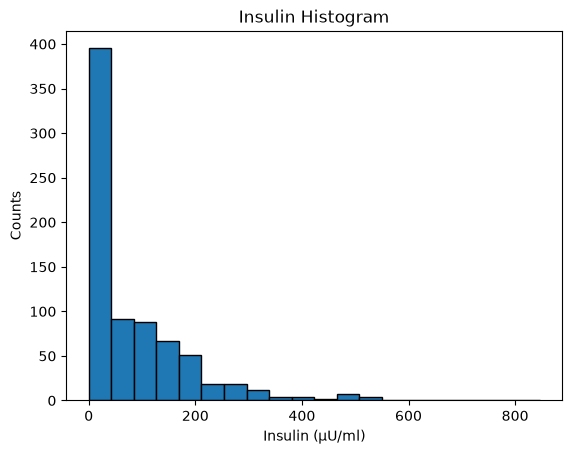

In [9]:
df['Insulin'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Insulin (μU/ml)')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

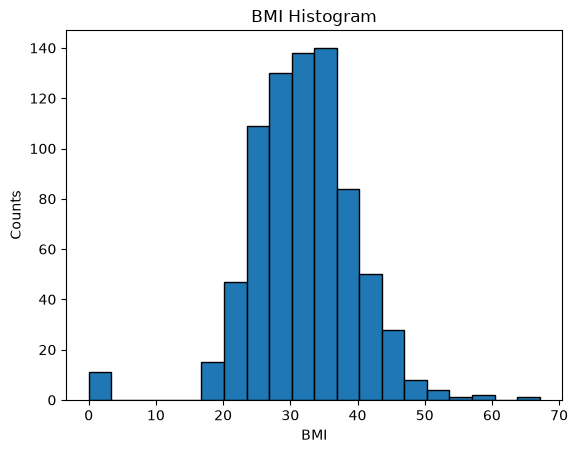

In [10]:
df['BMI'].hist(bins=20, edgecolor='black')
plt.title('BMI Histogram')
plt.xlabel('BMI')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

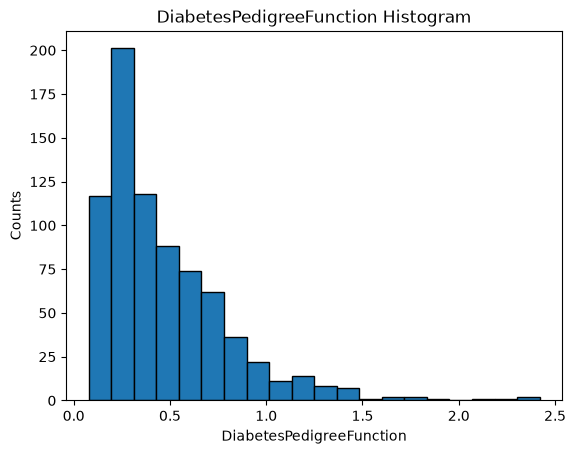

In [11]:
df['DiabetesPedigreeFunction'].hist(bins=20, edgecolor='black')
plt.title('DiabetesPedigreeFunction Histogram')
plt.xlabel('DiabetesPedigreeFunction')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

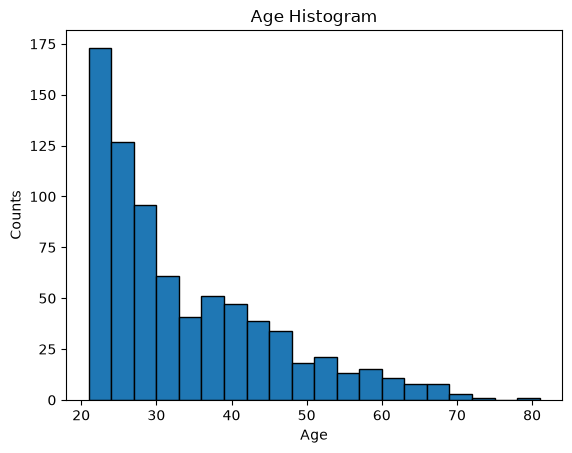

In [12]:
df['Age'].hist(bins=20, edgecolor='black')
plt.title('Age Histogram')
plt.xlabel('Age')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

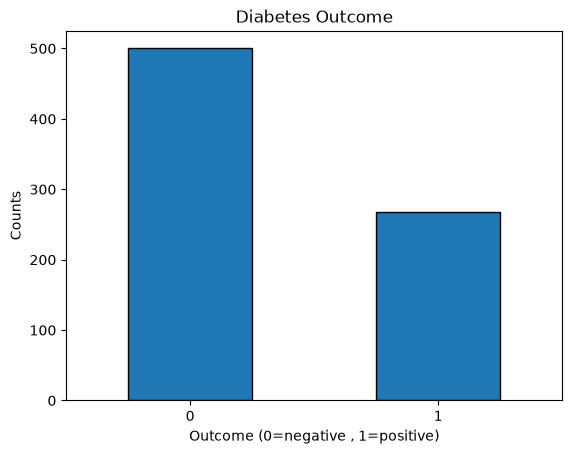

In [13]:
df['Outcome'].value_counts().sort_index().plot.bar(edgecolor='black')

plt.title('Diabetes Outcome')
plt.xlabel('Outcome (0=negative , 1=positive)')
plt.ylabel('Counts')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()

# Δημιουργία Numpy Arrays input(x) & targets (y), με τις μεταβλητές στο x και αποτέλεσμα (outcome) στο y 

In [14]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

# Χωρισμός dataset σε train-validation (70%-30%)

In [15]:
seed = 0
validation_size = 0.3

x_train, x_validation, y_train, y_validation = train_test_split(x, y, test_size=validation_size, random_state=seed)
x_train.shape, y_train.shape, x_validation.shape, y_validation.shape

((537, 8), (537,), (231, 8), (231,))

# Εμφάνιση πλήθους παραδειγμάτων εκπαίδευσης και επικύρωσης

In [16]:
print ("Training samples:", x_train.shape[0])
print ("Validation samples:", x_validation.shape[0])

Training samples: 537
Validation samples: 231


# Χρήση του Validation Set ως Test Set

Για την αξιολόγηση του μοντέλου χρησιμοποιούμε το σύνολο επικύρωσης (validation set) που δημιουργήθηκε στο προηγούμενο ερώτημα, καθώς ο διαχωρισμός των δεδομένων έχει ήδη πραγματοποιηθεί σε ποσοστό 70%–30%. Επομένως, δεν χρειάζεται να επαναλάβουμε τη διαδικασία.

In [17]:
x_test = x_validation
y_test = y_validation

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

# Εκπαίδευση Μοντέλου Λογιστικής Παλινδρόμησης

In [18]:
model = LogisticRegression(max_iter=5000, random_state=seed)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

# Υπoλογισμός ακρίβειας (accuracy score)

In [19]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

training_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

training_accuracy_percentage = round(training_accuracy*100, 2)
test_accuracy_percentage = round(test_accuracy*100, 2)

print(f'The accuracy of the training model is: {training_accuracy_percentage}')
print(f'The accuracy of the test model is: {test_accuracy_percentage}')

The accuracy of the training model is: 76.54
The accuracy of the test model is: 77.92


Επεξήγηση αποτελεσμάτων:

Η ακρίβεια του ταξινομητή Λογιστικής Παλινδρόμησης (Logistic Regression Classifier) στο σύνολο εκπαίδευσης (training set) είναι 76,54% και στο σύνολο ελέγχου (test set) είναι 77,92%. Υπάρχει μικρή διαφορά 1,38 ποσοστιαίων μονάδων με ελαφρώς υψηλότερη ακρίβεια του test set.

Η διαφορά πιθανόν να οφείλεται στον τυχαίο διαχωρισμό δεδομένων-παραδειγμάτων και στη διαφορετική δυσκολία τους προς επίλυση. 

Η μικρή απόκλιση είναι καλό δείγμα για την απόδοση του μοντέλου καθώς παρουσιάζει παρόμοια απόδοση στα δεδομένα εκπαίδευσης και ελέγχου (train + test set), χωρίς σοβαρές ενδείξεις υπερπροσαρμογής (overfitting).

# Κανονικοποίηση δεδομένων

In [20]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Εκπαίδευση - Επαλήθευση Μοντέλου

In [21]:
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print('The accuracy of the model is:', accuracy_percentage)

The accuracy of the model is: 77.92


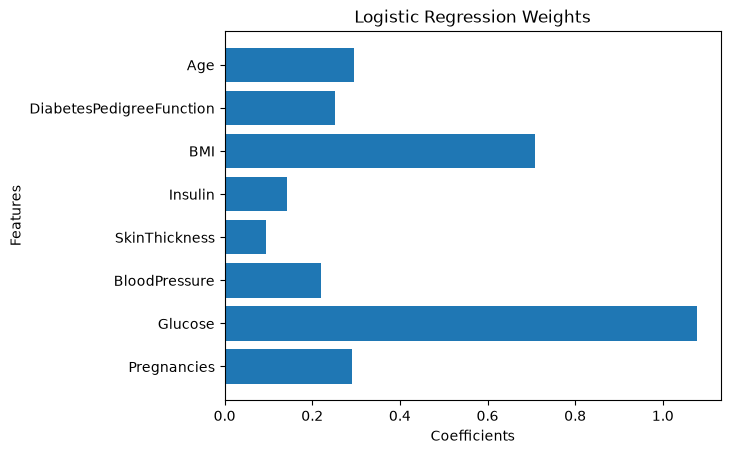

In [22]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Coefficients')
plt.ylabel('Features')
plt.show()

Από το παραπάνω διάγραμμα παρατηρούμε ότι η γλυκόζη (glucose) έχει τον μεγαλύτερο συντελεστή και επομένως την μεγαλύτερη επίδραση στη γραμμική συνάρτηση του μοντέλου.

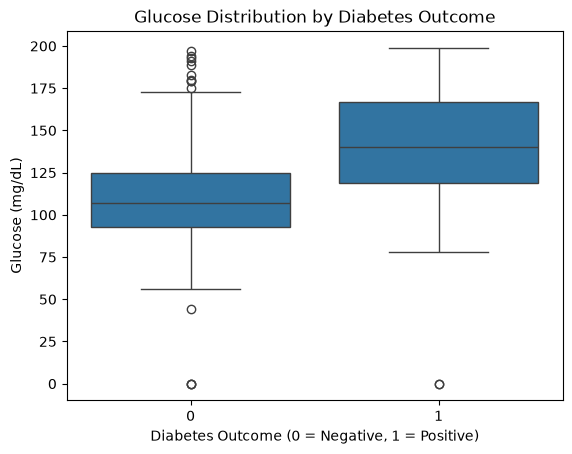

In [23]:
import seaborn as sns

sns.boxplot(data=df, x='Outcome', y='Glucose')

plt.title('Glucose Distribution by Diabetes Outcome')
plt.xlabel('Diabetes Outcome (0 = Negative, 1 = Positive)')
plt.ylabel('Glucose (mg/dL)')
plt.show()

Με το παραπάνω boxplot φαίνεται οπτικά ότι οι τιμές γλυκόζης είναι υψηλότερες στους ασθενείς με διαβήτη. 

Να σημειωθεί ότι η υψηλή γλυκόζη συσχετίζεται με τον διαβήτη στο dataset, αλλά δεν αποδεικνύεται πως προκαλεί διαβήτη (correlation ≠ causation) ή πως το μοντέλο προβλέπει την εμφάνιση του στο μέλλον. 

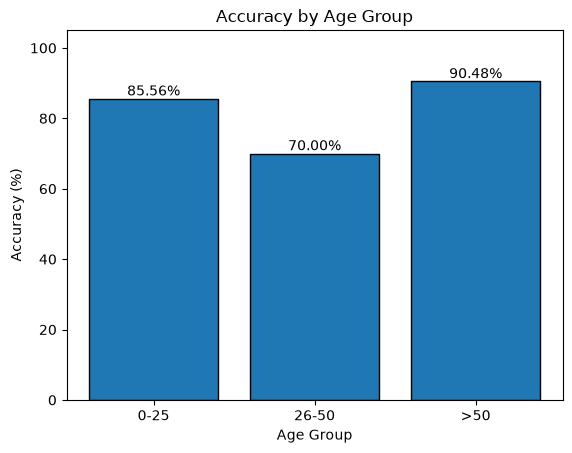

In [24]:

age = x_test[:,7] # η ηλικία έχει index 7 στο df

# χωρίζω τις ηλικίες σε διαστήματα
age_groups = pd.cut(
    age,
    bins=[0, 25, 50, np.inf],
    labels=['0-25', '26-50', '>50']
)

prediction_results = model.predict(x_test_scaled) == y_test

age_accuracy = (
    pd.Series(prediction_results).groupby(age_groups, observed=True).mean() * 100
)

# δημιουργία  bar plot
bars = plt.bar(age_accuracy.index, age_accuracy.values, edgecolor='black')
plt.bar_label(bars, fmt='%.2f%%') # εμφάνιση ποσσοτού με 2 δεκαδικά

plt.title('Accuracy by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105) # μεγαλώνω λίγο το ύψος του άξονα y για καλύτερη απεικόνιση του γραφήματος
plt.grid(False)
plt.show()


Παρατηρούμε ότι ο ταξινομητής λογιστικής παλινδρόμησης δεν έχει την ίδια ακρίβεια σε όλες τις ηλικιακές ομάδες. Η ακρίβεια ανέρχεται σε:

- 85,56% για τις ηλικίες 0-25
- 70% για τις ηλικίες 26-50 
- 90,48% για τις ηλικίες άνω των 50

Παρά το γεγονός, ότι η μεγαλύτερη ακρίβεια παρατηρείται στις ηλικίες άνω των 50 ετών (90,48%), το αποτέλεσμα βασίζεται σε μικρό δείγμα (21 ασθενών), μειώνοντας την αξιοπιστία της εκτίμησης.

Η ομάδα 0-25 ετών παρουσιάζει και αυτή υψηλή ακρίβεια (85,56%) αλλά σε μεγαλύτερο δείγμα (90 ασθενών).

Η χαμηλότερη ακρίβεια παρατηρείται στις ομάδα 26-50 ετών (70%), η οποία έχει το μεγαλύτερο δείγμα (120 ασθενών).

Συνεπώς, υπάρχουν διαφορές στην απόδοση του ταξινομητή μεταξύ ηλικιακών ομάδα και απαιτείται προσοχή στην ερμηνεία της υψηλής ακρίβειας των ασθενών ηλικίας άνω των 50, λόγου μικρού δείγματος.

Το χειρότερο για τον ταξινομητή είναι να προβλέπει ότι κάποιος ασθενής δεν έχει διαβήτη, ενώ έχει (false negative), καθώς η εφαρμογή είναι ιατρική. Μια λανθασμένη πρόβλεψη μπορεί να οδηγήσει σε καθυστέρηση της διάγνωσης και θεραπείας, με σοβαρές επιπτώσεις στην υγεία του ασθενή.

Ο γιατρός προτιμάει το μοντέλο να προβλέπει ότι κάποιος ασθενής έχει διαβήτη, ενώ δεν έχει (false positive), καθώς ο γιατρός θα καλέσει τον ασθενή για περαιτέρω εξέταση όπου θα διαπιστωθεί αν πραγματικά έχει διαβήτη.


# Μέρος 2 – Γραμμική Παλινδρόμηση

# Φόρτωση συνόλου δεδομένων (dataset)

In [25]:
df = pd.read_csv('diabetes.csv')

# Δημιουργία Numpy Arrays input(x) & targets (y), με τις μεταβλητές Pregnancies, Blood Pressure, BMI, Age στο x και τη μεταβλητή Glucose στο y 

In [26]:
input_df = df[['Pregnancies','BloodPressure', 'BMI', 'Age']]
targets_df = df['Glucose']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 4), (768,))

# Χωρισμός dataset σε train-validation (70%-30%)

In [27]:
seed = 0
validation_size = 0.3

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=validation_size, random_state=seed)
x_train.shape, y_train.shape, x_val.shape, y_val.shape

((537, 4), (537,), (231, 4), (231,))

# Εκπαίδευση Μοντέλου Γραμμικής Παλινδρόμησης

In [28]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_val)


# Υπολογισμός Mean Squared Error (MSE) και Mean Absolute Error (MAE)

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)

print('Mean Squared Error (MSE):' , mse)
print('Mean Absolute Error (MAE):' , mae)

Mean Squared Error (MSE): 929.88834927469
Mean Absolute Error (MAE): 23.599990462075155


Από τα αποτελέσματα προκύπτει ότι το μοντέλο παρουσιάζει MSE = 929,89 και MAE = 23,60. Παρόλο που το MSE φαίνεται αρκετά μεγάλο, αυτό οφείλεται στο γεγονός ότι υπολογίζεται με το τετράγωνο των σφαλμάτων, με αποτέλεσμα οι μεγαλύτερες αποκλίσεις να επηρεάζουν περισσότερο την τελική τιμή.

Στη συγκεκριμένη περίπτωση θα επέλεγα το MAE, κυρίως επειδή είναι πιο εύκολο να ερμηνευτεί. Μας δείχνει ότι οι προβλέψεις του μοντέλου αποκλίνουν κατά μέσο όρο περίπου 23,6 mg/dL από τις πραγματικές τιμές γλυκόζης. Αντίθετα, το MSE δεν εκφράζεται στην ίδια μονάδα με τη γλυκόζη, οπότε είναι δυσκολότερο να καταλάβουμε άμεσα πόσο απέχει μια πρόβλεψη από την πραγματική τιμή.

Βέβαια, επειδή πρόκειται για ιατρικά δεδομένα, το MSE έχει και αυτό τη χρησιμότητά του, αφού δίνει μεγαλύτερη βαρύτητα σε μεγάλες αποκλίσεις που μπορεί να είναι σημαντικές. Παρ' όλα αυτά, θεωρώ το MAE καταλληλότερο για την παρουσίαση και την ερμηνεία της μέσης απόδοσης του μοντέλου.

# Κανονικοποίηση 

In [30]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)

# Ομαλοποίηση 

In [31]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

model_linear = LinearRegression()
model_ridge = Ridge(alpha=1.0)
model_lasso = Lasso(alpha=1.0)
model_elastic = ElasticNet(alpha=1.0, l1_ratio=0.5)

model_linear.fit(x_train_scaled, y_train)
model_ridge.fit(x_train_scaled, y_train)
model_lasso.fit(x_train_scaled, y_train)
model_elastic.fit(x_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1.0
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


# Σύγκριση συντελεστών

In [32]:
comparison = pd.DataFrame({
    'Feature': input_df.columns,
    'LinearRegression': np.abs(model_linear.coef_),
    'Ridge': np.abs(model_ridge.coef_),
    'Lasso': np.abs(model_lasso.coef_),
    'ElasticNet': np.abs(model_elastic.coef_)
})

display(comparison)

,Feature,LinearRegression,Ridge,Lasso,ElasticNet
0,Pregnancies,0.572175,0.558535,0.000000,0.590500
1,BloodPressure,0.793616,0.800440,0.208438,1.212832
2,BMI,7.562080,7.546409,6.742096,4.648847
3,Age,9.214627,9.188744,8.039071,5.337004


# Οπτικοποίηση σημαντικότητας συντελεστών

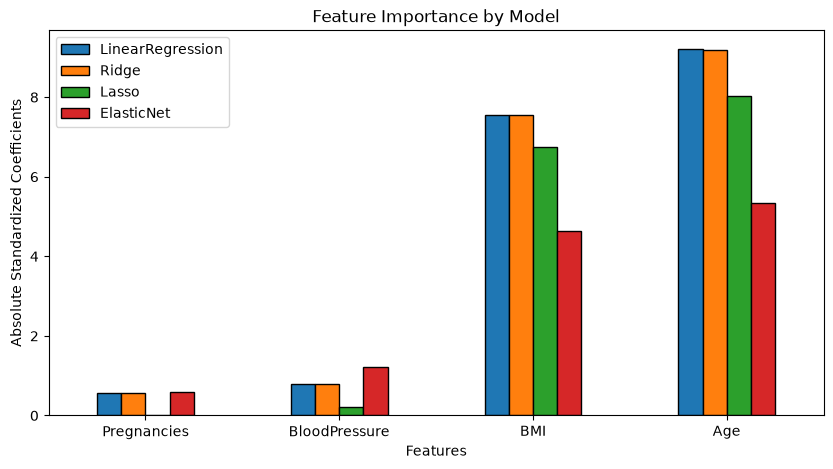

In [33]:
comparison.plot(x='Feature', kind='bar', edgecolor='black', figsize=(10, 5))

plt.title('Feature Importance by Model')
plt.xlabel('Features')
plt.ylabel('Absolute Standardized Coefficients')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()

Από τα αποτελέσματα φαίνεται ότι η ηλικία εμφανίζει τον μεγαλύτερο απόλυτο συντελεστή στην πρόβλεψη της γλυκόζης και στα τέσσερα μοντέλα, ενώ ακολουθεί το BMI.

Στο Ridge οι συντελεστές παραμένουν σχεδόν ίδιοι με αυτούς της απλής Γραμμικής Παλινδρόμησης. Στο Lasso παρατηρείται μεγαλύτερη μείωση, ενώ ο συντελεστής των εγκυμοσυνών (Pregnancies) μηδενίζεται. Αντίστοιχα, το Elastic Net μειώνει τους συντελεστές, αλλά η ηλικία και το BMI εξακολουθούν να έχουν τις μεγαλύτερες τιμές.

Επομένως, με βάση τη σύγκριση των συντελεστών μετά την κανονικοποίηση των δεδομένων, η ηλικία φαίνεται να είναι η σημαντικότερη μεταβλητή για την πρόβλεψη της γλυκόζης, με το BMI να ακολουθεί.